# Taxonomy manipulations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ete3 import NCBITaxa

## Make Tree of Life

- Use taxonomic rank Phylum for all domains of life (including viruses)

In [2]:
ncbi = NCBITaxa()

In [ ]:
# Make a Tree of Life (Domains → Phyla)

db = ncbi.db

groups = ["Eukaryota", "Archaea", "Bacteria", "Viruses"]

name2taxid = ncbi.get_name_translator(groups)
root_taxids = [name2taxid[g][0] for g in groups]

# Exclude problematic / low-quality phyla (NOW includes candidate again)
bad_words = [
    "environmental",
    "uncultured",
    "unclassified",
    "incertae sedis",
    "metagenome",
    "candidate",
    "candidatus"
]

# ----------------------
# get ONLY phyla via SQL
# ----------------------
phyla = db.execute("""
    SELECT taxid FROM species
    WHERE rank = 'phylum'
""").fetchall()

phyla = [p[0] for p in phyla]

# ----------------------
# keep only those under selected domains
# ----------------------
lineages = ncbi.get_lineage_translator(phyla)

selected_phyla = []

for taxid in phyla:
    lineage = lineages.get(taxid, [])
    if any(root in lineage for root in root_taxids):
        selected_phyla.append(taxid)

# ----------------------
# filter names
# ----------------------
names = ncbi.get_taxid_translator(selected_phyla)

filtered_phyla = [
    t for t in selected_phyla
    if not any(w in names[t].lower() for w in bad_words)
]

# ----------------------
# build tree (with intermediate nodes)
# ----------------------
tree = ncbi.get_topology(filtered_phyla, intermediate_nodes=True)

# ----------------------
# prune to phyla (keep structure)
# ----------------------
taxid2node = {
    n.taxid: n for n in tree.traverse() if hasattr(n, "taxid")
}

nodes_to_keep = [taxid2node[t] for t in filtered_phyla if t in taxid2node]

tree.prune(nodes_to_keep, preserve_branch_length=False)

# ----------------------
# enforce leveled cladogram
# ----------------------
root = tree.get_tree_root()

for node in tree.traverse("preorder"):
    if not node.is_root():
        node.dist = 1

max_dist = max(root.get_distance(leaf) for leaf in tree)

for leaf in tree:
    current_dist = root.get_distance(leaf)
    leaf.dist += (max_dist - current_dist)

root.dist = 0

# ----------------------
# rename nodes first (needed for sorting)
# ----------------------
all_taxa = [n.taxid for n in tree.traverse() if hasattr(n, "taxid")]
taxid2name = ncbi.get_taxid_translator(all_taxa)

for node in tree.traverse():
    if hasattr(node, "taxid"):
        name = taxid2name.get(node.taxid, str(node.taxid))
        clean_name = name.replace("'", "")
        node.name = clean_name

# ----------------------
# enforce alphabetical ordering everywhere
# (handles polytomies AND pairs)
# ----------------------
def sort_clade(node):
    if node.is_leaf():
        return
    node.children.sort(key=lambda c: c.name)
    for child in node.children:
        sort_clade(child)

sort_clade(root)

# ----------------------
# OPTIONAL: enforce domain order at root
# ----------------------
domain_order = {name: i for i, name in enumerate(groups)}

def get_domain_index(node):
    lineage = ncbi.get_lineage(node.taxid) if hasattr(node, "taxid") else []
    for d_name, d_taxid in name2taxid.items():
        if d_taxid[0] in lineage:
            return domain_order[d_name]
    return 999

root.children.sort(key=get_domain_index)

# ----------------------
# quote names for Newick
# ----------------------
for node in tree.traverse():
    node.name = "'" + node.name + "'"

# ----------------------
# export
# ----------------------
tree.write(outfile="../additional_files/tree_of_life/tree_of_life_phyla.nwk", format=1)

print("Tree written to tree_of_life_phyla.nwk")

Tree written to tree_of_life_phyla.nwk


## Make a heatmap of MMseqs2 hits with domain coverage

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ete3 import NCBITaxa

In [ ]:
file_hits = "../additional_files/mmseqs_data/best_ensembl_nr_hits_per_species_extended.tsv.gz"
df_hits = pd.read_csv(file_hits, sep='\t')

df_hits = df_hits[df_hits['evalue'] <= 0.001]

for column in ['domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species']:
    df_hits[column].fillna('Other', inplace=True)

df_hits["protein_name"] = (df_hits["gene_name"].str.extract(r"^[^\s]+\s(.+?)\s\["))
df_hits["protein_name"] = df_hits["protein_name"].fillna(df_hits["gene_name"])

In [ ]:
file_domains = "../additional_files/human_isg_domains/human_dais_curated_domain_positions.csv"
df_domains = pd.read_csv(file_domains)

df_domains.rename(columns={
    'gene_name': 'gene'
}, inplace=True)

df_domains['domain_start'] = df_domains['domain_position'].apply(lambda x: int(x.split('-')[0]))
df_domains['domain_end'] = df_domains['domain_position'].apply(lambda x: int(x.split('-')[-1]))

df_domains['heatmap_label'] = df_domains['gene'].astype(str) + ' ' + df_domains['domain_label'].astype(str) + ' ' + df_domains['domain_position'].astype(str)

In [11]:
def calc_domain_coverage(hit_row, domain_df, include=False):
    
    gene = hit_row['gene']
    qstart = hit_row['qstart']
    qend = hit_row['qend']

    domains = domain_df[domain_df['gene'] == gene]

    coverage_list = []

    for _, d in domains.iterrows():

        dstart = d['domain_start']
        dend = d['domain_end']
        label = d['domain_label']

        if include:
            inclusion_status = d['include']
            if inclusion_status != 'yes':
                continue

        # calculate overlap
        overlap_start = max(qstart, dstart)
        overlap_end = min(qend, dend)

        overlap = max(0, overlap_end - overlap_start + 1)

        domain_len = dend - dstart + 1

        percent = (overlap / domain_len) * 100 if domain_len > 0 else 0

        coverage_list.append(f"{label}:{percent:.1f}")

    return "|".join(coverage_list)

In [12]:
df_hits['domain_coverage'] = df_hits.apply(
    lambda row: calc_domain_coverage(row, df_domains),
    axis=1
)

In [13]:
df_hits[df_hits['gene'] == 'BTN3A3'].head(3)

,gene,target,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,kingdom,phylum,class,order,family,genus,species,protein_sequence,protein_name,domain_coverage
95921,BTN3A3,ENSP00000244519.2,1.000,584,0,0,1,584,1.0,584,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,SP:100.0|IgV:100.0|IgC:100.0|TMD:100.0|CCD:100...
95922,BTN3A3,XP_030868142.2,0.994,584,3,0,1,584,1.0,584,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Gorilla,Gorilla gorilla,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,butyrophilin subfamily 3 member A3 isoform X1,SP:100.0|IgV:100.0|IgC:100.0|TMD:100.0|CCD:100...
95923,BTN3A3,ENSPTRP00000030422.3,0.993,584,4,0,1,584,1.0,584,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan troglodytes,MKMASSLAFLLLNFHVSLFLVQLLTPCSAQFSVLGPSGPILAMVGE...,BTN3A3,SP:100.0|IgV:100.0|IgC:100.0|TMD:100.0|CCD:100...


In [ ]:
from ete3 import Tree

tree = Tree("../additional_files/tree_of_life/tree_of_life_phyla.nwk", format=1)

In [15]:
tips = [leaf.name.strip("'") for leaf in tree.iter_leaves()]
name2taxid = ncbi.get_name_translator(tips)
tip_taxids = {name: name2taxid[name][0] for name in tips if name in name2taxid}

species_list = df_hits["species"].dropna().unique()
name2taxid = ncbi.get_name_translator(species_list)

species_taxid = {
    name: ids[0]
    for name, ids in name2taxid.items()
}

lineages = {
    name: ncbi.get_lineage(taxid)
    for name, taxid in species_taxid.items()
}

In [16]:
domains = df_domains['heatmap_label'].unique()

heatmap_df = pd.DataFrame(
    0.0,
    index=tips,
    columns=domains
)

for gene in df_hits["gene"].unique():
    heatmap_df[f"{gene}_best"] = 0

In [ ]:
for _, row in df_hits.iterrows():

    species = row["species"]
    gene = row["gene"]
    qcov = row["qcov"]

    if species not in lineages:
        continue

    lineage = lineages[species]

    # parse domain coverage
    domain_string = row["domain_coverage"]
    domains = {}

    for d in domain_string.split("|"):
        name, cov = d.split(":")
        domains[name] = float(cov)

    for taxon, taxid in tip_taxids.items():

        if taxid in lineage:

            # check if this hit is better
            if qcov > heatmap_df.loc[taxon, f"{gene}_best"]:

                # store best score
                heatmap_df.loc[taxon, f"{gene}_best"] = qcov

                # fill domain columns
                for domain, cov in domains.items():

                    prefix = f"{gene} {domain}"

                    matching_cols = [c for c in heatmap_df.columns if c.startswith(prefix)]

                    for col in matching_cols:
                        heatmap_df.loc[taxon, col] = cov

In [18]:
heatmap_df = heatmap_df.drop(columns=[c for c in heatmap_df.columns if c.endswith("_best")])

# ensure row order matches tree
heatmap_df = heatmap_df.reindex(index=tips)

# ensure column order matches domain definition
heatmap_df = heatmap_df.reindex(columns=df_domains['heatmap_label'].unique())

In [20]:
heatmap_df.loc["Chordata"]

BST2 FL 1-180            100.0
BTN3A1 SP 1-29           100.0
BTN3A1 IgV 30-145        100.0
BTN3A1 IgC 146-254       100.0
BTN3A1 TMD 255-271       100.0
                         ...  
ZNFX1 linker 311-331     100.0
ZNFX1 2AAA+ 336-1290     100.0
ZNFX1 6ZNFs 1291-1629    100.0
ZNFX1 CCD 1630-1824      100.0
ZNFX1 RZ 1825-1918       100.0
Name: Chordata, Length: 108, dtype: float64

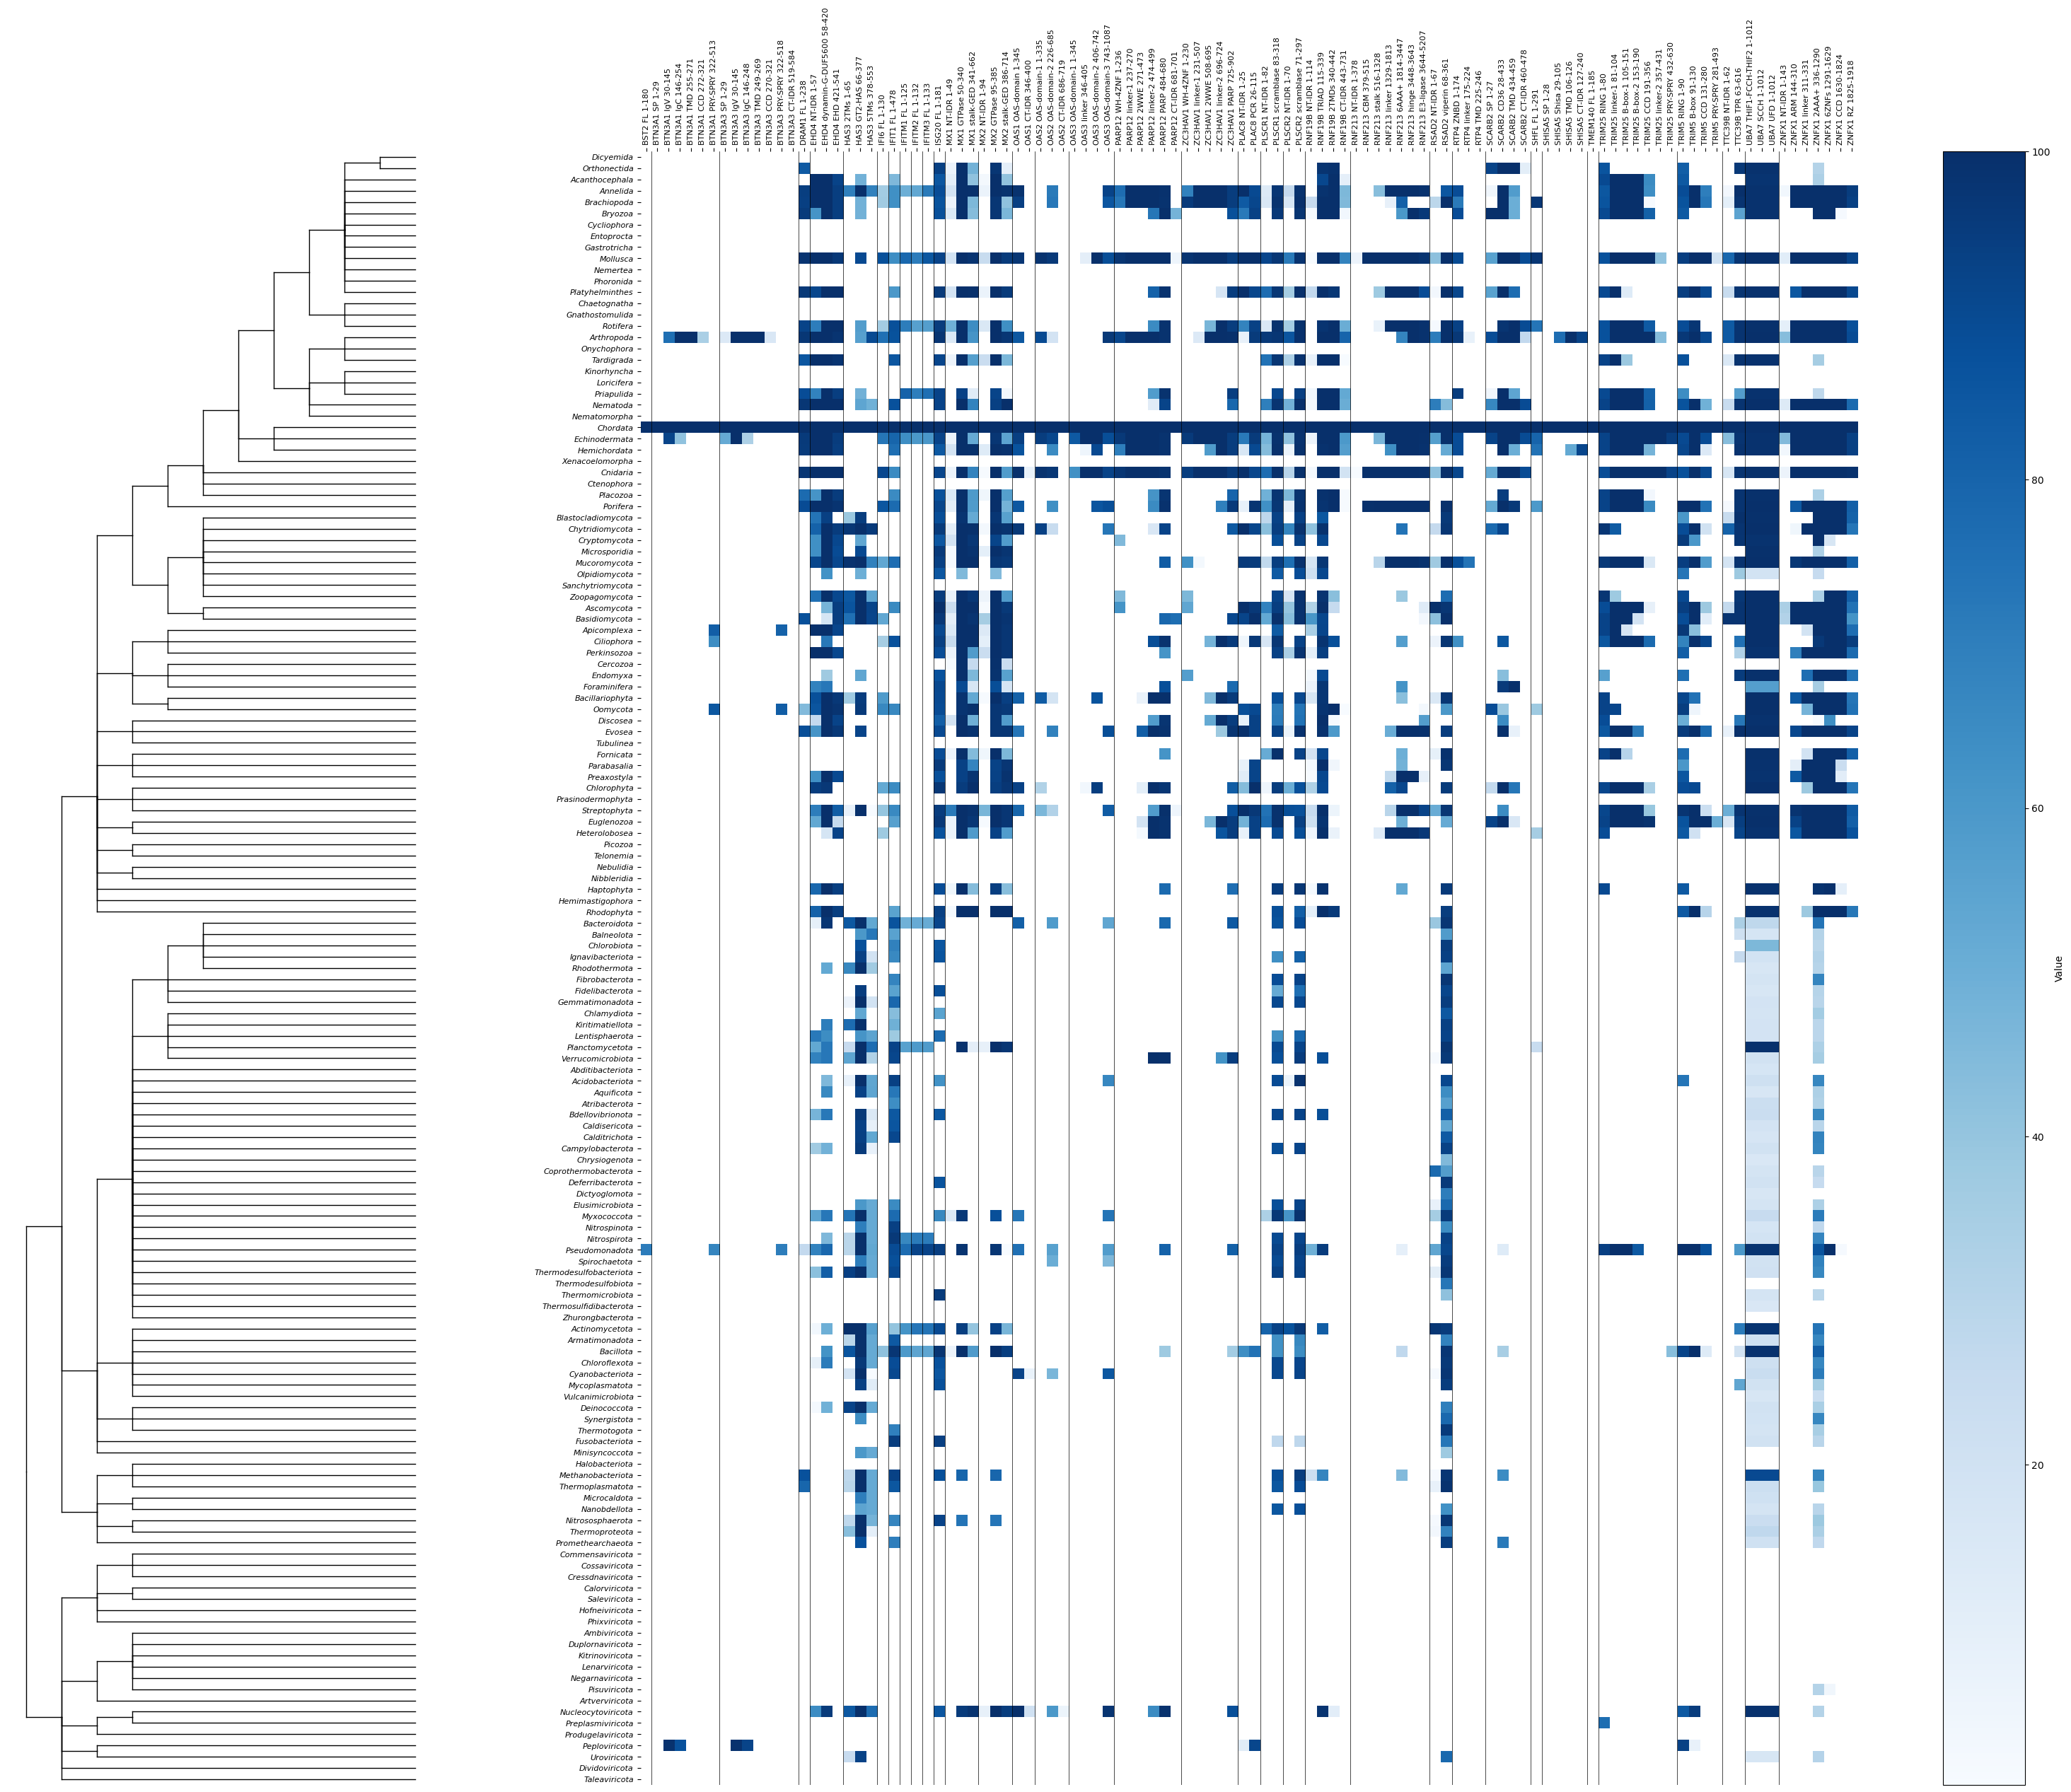

In [ ]:
# Tree of life

import matplotlib.cm as cm

data = heatmap_df.values

fig = plt.figure(figsize=(40,30))
gs = fig.add_gridspec(ncols=2, nrows=1, width_ratios=[1,4], wspace=0.05)
ax_tree = fig.add_subplot(gs[0])
ax_heat = fig.add_subplot(gs[1])

# ------------------------
# calculate tree coordinates
# ------------------------

leaf_positions = {leaf.name.strip("'"): i + 0.5 for i, leaf in enumerate(tree.iter_leaves())}
x_coords = {}
y_coords = {}

# assign leaf positions
for leaf in tree.iter_leaves():
    name = leaf.name.strip("'")
    x_coords[leaf] = leaf.get_distance(tree)
    y_coords[leaf] = leaf_positions[name]

# assign internal node positions recursively
for node in tree.traverse(strategy='postorder'):
    if node not in x_coords:
        x_coords[node] = node.get_distance(tree)
        y_coords[node] = np.mean([y_coords[child] for child in node.children])

# ------------------------
# draw branches
# ------------------------

for node in tree.traverse():
    for child in node.children:
        # horizontal
        ax_tree.plot(
            [x_coords[node], x_coords[child]],
            [y_coords[child], y_coords[child]],
            lw=1,
            color='black'
        )
        # vertical
        ax_tree.plot(
            [x_coords[node], x_coords[node]],
            [y_coords[node], y_coords[child]],
            lw=1,
            color='black'
        )

ax_tree.set_ylim(len(tips), 0)
ax_tree.axis('off')
# ------------------------
# draw heatmap
# ------------------------
masked_data = np.ma.masked_where(data == 0, data)

#cmap = plt.cm.viridis.copy()
#cmap = plt.cm.YlGnBu.copy()
cmap = plt.cm.Blues.copy()
cmap.set_bad(color='white')

im = ax_heat.imshow(masked_data, aspect='equal', interpolation='nearest', cmap=cmap)

# ------------------------
# add vertical separators by gene


# extract gene names (assuming "gene domain" format)
genes = [col.split()[0] for col in heatmap_df.columns]

# find boundaries where gene changes
boundaries = []
for i in range(1, len(genes)):
    if genes[i] != genes[i - 1]:
        boundaries.append(i)

# draw vertical lines
for b in boundaries:
    ax_heat.axvline(b - 0.5, color='black', lw=0.5)

# ------------------------

# remove heatmap border
for spine in ax_heat.spines.values():
    spine.set_visible(False)

# y-axis: taxa
ax_heat.set_yticks(range(len(tips)))
ax_heat.set_yticklabels(
    tips,
    fontsize=8,        # increase font size
    fontstyle='italic' # make italic
    #fontweight='bold'   # make bold
)

# x-axis: gene names
ax_heat.set_xticks(range(len(heatmap_df.columns)))
ax_heat.set_xticklabels(
    heatmap_df.columns,
    rotation=90,
    fontsize=8,        # increase font size
    #fontstyle='italic', # italic
    #fontweight='bold'   # bold
    #ha='right'
)

# move x-axis labels to top
ax_heat.xaxis.set_ticks_position('top')
ax_heat.xaxis.set_label_position('top')

# colorbar
cbar = fig.colorbar(im, ax=ax_heat)
cbar.set_label('Value')

plt.savefig('../figures/heatmap_mmseq_tree_of_life_best_region_hit_per_taxa_query_coverage.svg', format='svg', bbox_inches='tight')

plt.show()

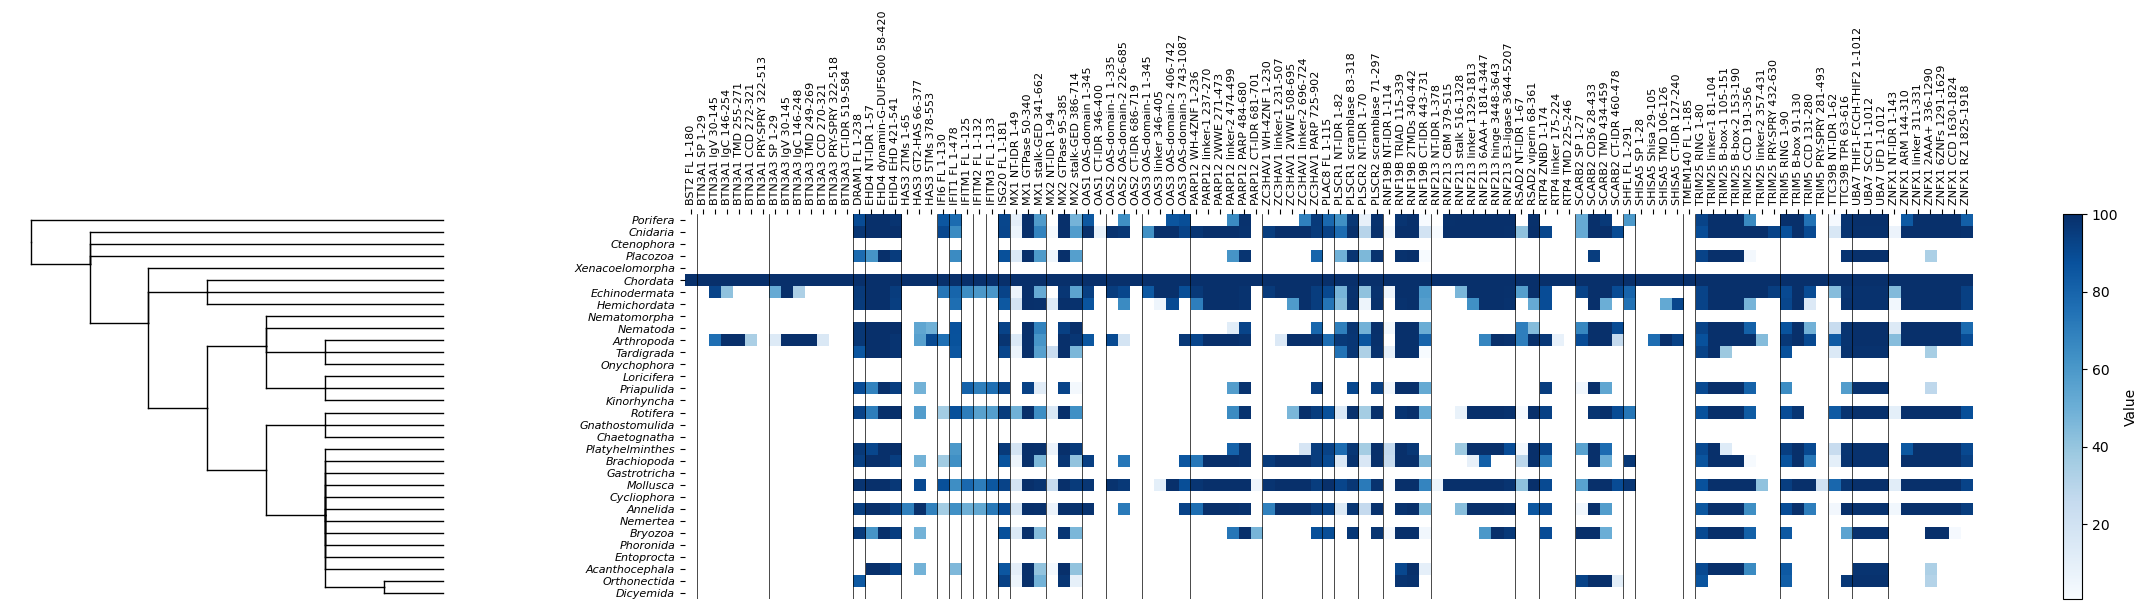

In [ ]:
# Metazoa

import matplotlib.cm as cm

data = heatmap_df.values

fig = plt.figure(figsize=(30,5))
gs = fig.add_gridspec(ncols=2, nrows=1, width_ratios=[1,4], wspace=0.05)
ax_tree = fig.add_subplot(gs[0])
ax_heat = fig.add_subplot(gs[1])

# ------------------------
# calculate tree coordinates
# ------------------------

leaf_positions = {leaf.name.strip("'"): i + 0.5 for i, leaf in enumerate(tree.iter_leaves())}
x_coords = {}
y_coords = {}

# assign leaf positions
for leaf in tree.iter_leaves():
    name = leaf.name.strip("'")
    x_coords[leaf] = leaf.get_distance(tree)
    y_coords[leaf] = leaf_positions[name]

# assign internal node positions recursively
for node in tree.traverse(strategy='postorder'):
    if node not in x_coords:
        x_coords[node] = node.get_distance(tree)
        y_coords[node] = np.mean([y_coords[child] for child in node.children])

# ------------------------
# draw branches
# ------------------------

for node in tree.traverse():
    for child in node.children:
        # horizontal
        ax_tree.plot(
            [x_coords[node], x_coords[child]],
            [y_coords[child], y_coords[child]],
            lw=1,
            color='black'
        )
        # vertical
        ax_tree.plot(
            [x_coords[node], x_coords[node]],
            [y_coords[node], y_coords[child]],
            lw=1,
            color='black'
        )

ax_tree.set_ylim(len(tips), 0)
ax_tree.axis('off')
# ------------------------
# draw heatmap
# ------------------------
masked_data = np.ma.masked_where(data == 0, data)

#cmap = plt.cm.viridis.copy()
#cmap = plt.cm.YlGnBu.copy()
cmap = plt.cm.Blues.copy()
cmap.set_bad(color='white')

im = ax_heat.imshow(masked_data, aspect='equal', interpolation='nearest', cmap=cmap)

# ------------------------
# add vertical separators by gene


# extract gene names (assuming "gene domain" format)
genes = [col.split()[0] for col in heatmap_df.columns]

# find boundaries where gene changes
boundaries = []
for i in range(1, len(genes)):
    if genes[i] != genes[i - 1]:
        boundaries.append(i)

# draw vertical lines
for b in boundaries:
    ax_heat.axvline(b - 0.5, color='black', lw=0.5)

# ------------------------

# remove heatmap border
for spine in ax_heat.spines.values():
    spine.set_visible(False)

# y-axis: taxa
ax_heat.set_yticks(range(len(tips)))
ax_heat.set_yticklabels(
    tips,
    fontsize=8,        # increase font size
    fontstyle='italic' # make italic
    #fontweight='bold'   # make bold
)

# x-axis: gene names
ax_heat.set_xticks(range(len(heatmap_df.columns)))
ax_heat.set_xticklabels(
    heatmap_df.columns,
    rotation=90,
    fontsize=8,        # increase font size
    #fontstyle='italic', # italic
    #fontweight='bold'   # bold
    #ha='right'
)

# move x-axis labels to top
ax_heat.xaxis.set_ticks_position('top')
ax_heat.xaxis.set_label_position('top')

# colorbar
cbar = fig.colorbar(im, ax=ax_heat)
cbar.set_label('Value')

plt.savefig('../figures/heatmap_mmseq_metazoa_best_region_hit_per_taxa_query_coverage.svg', format='svg', bbox_inches='tight')

plt.show()

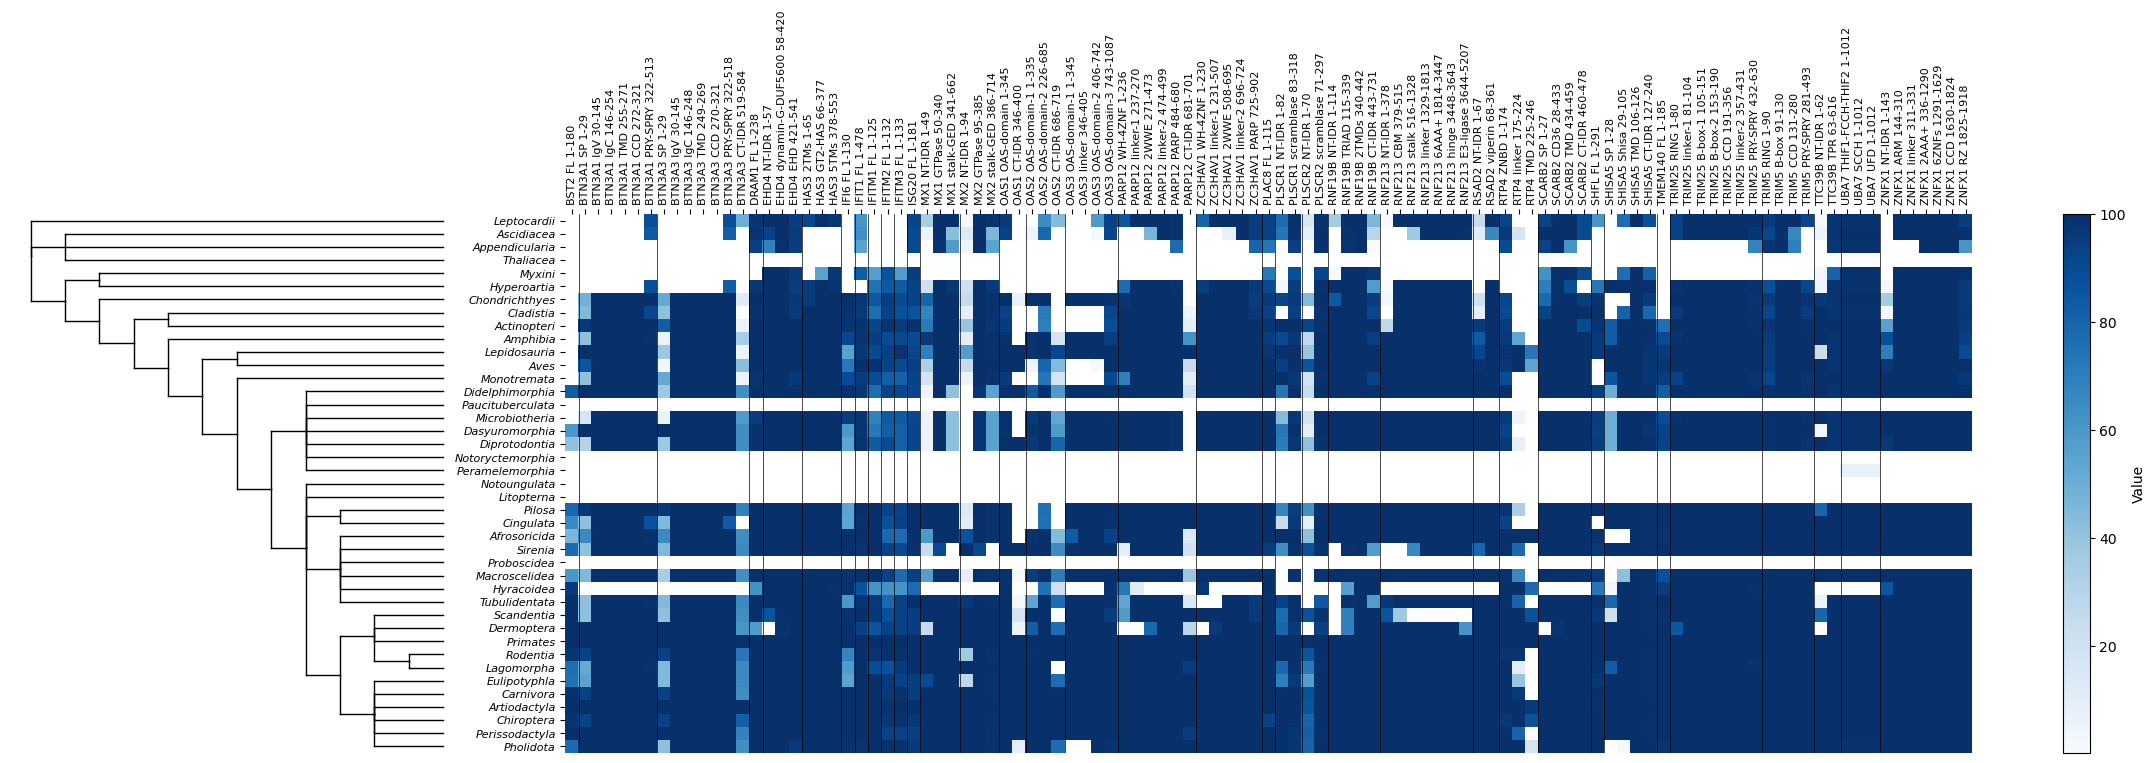

In [ ]:
# Chordata

import matplotlib.cm as cm

data = heatmap_df.values

fig = plt.figure(figsize=(30,7))
gs = fig.add_gridspec(ncols=2, nrows=1, width_ratios=[1,4], wspace=0.05)
ax_tree = fig.add_subplot(gs[0])
ax_heat = fig.add_subplot(gs[1])

# ------------------------
# calculate tree coordinates
# ------------------------

leaf_positions = {leaf.name.strip("'"): i + 0.5 for i, leaf in enumerate(tree.iter_leaves())}
x_coords = {}
y_coords = {}

# assign leaf positions
for leaf in tree.iter_leaves():
    name = leaf.name.strip("'")
    x_coords[leaf] = leaf.get_distance(tree)
    y_coords[leaf] = leaf_positions[name]

# assign internal node positions recursively
for node in tree.traverse(strategy='postorder'):
    if node not in x_coords:
        x_coords[node] = node.get_distance(tree)
        y_coords[node] = np.mean([y_coords[child] for child in node.children])

# ------------------------
# draw branches
# ------------------------

for node in tree.traverse():
    for child in node.children:
        # horizontal
        ax_tree.plot(
            [x_coords[node], x_coords[child]],
            [y_coords[child], y_coords[child]],
            lw=1,
            color='black'
        )
        # vertical
        ax_tree.plot(
            [x_coords[node], x_coords[node]],
            [y_coords[node], y_coords[child]],
            lw=1,
            color='black'
        )

ax_tree.set_ylim(len(tips), 0)
ax_tree.axis('off')
# ------------------------
# draw heatmap
# ------------------------
masked_data = np.ma.masked_where(data == 0, data)

#cmap = plt.cm.viridis.copy()
#cmap = plt.cm.YlGnBu.copy()
cmap = plt.cm.Blues.copy()
cmap.set_bad(color='white')

im = ax_heat.imshow(masked_data, aspect='equal', interpolation='nearest', cmap=cmap)

# ------------------------
# add vertical separators by gene


# extract gene names (assuming "gene domain" format)
genes = [col.split()[0] for col in heatmap_df.columns]

# find boundaries where gene changes
boundaries = []
for i in range(1, len(genes)):
    if genes[i] != genes[i - 1]:
        boundaries.append(i)

# draw vertical lines
for b in boundaries:
    ax_heat.axvline(b - 0.5, color='black', lw=0.5)

# ------------------------

# remove heatmap border
for spine in ax_heat.spines.values():
    spine.set_visible(False)

# y-axis: taxa
ax_heat.set_yticks(range(len(tips)))
ax_heat.set_yticklabels(
    tips,
    fontsize=8,        # increase font size
    fontstyle='italic' # make italic
    #fontweight='bold'   # make bold
)

# x-axis: gene names
ax_heat.set_xticks(range(len(heatmap_df.columns)))
ax_heat.set_xticklabels(
    heatmap_df.columns,
    rotation=90,
    fontsize=8,        # increase font size
    #fontstyle='italic', # italic
    #fontweight='bold'   # bold
    #ha='right'
)

# move x-axis labels to top
ax_heat.xaxis.set_ticks_position('top')
ax_heat.xaxis.set_label_position('top')

# colorbar
cbar = fig.colorbar(im, ax=ax_heat)
cbar.set_label('Value')

plt.savefig('../figures/heatmap_mmseq_chordata_best_region_hit_per_taxa_query_coverage.svg', format='svg', bbox_inches='tight')

plt.show()